In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv("austin_weather.csv")

In [3]:
data.head()

,Date,TempHighF,TempAvgF,TempLowF,DewPointHighF,DewPointAvgF,DewPointLowF,HumidityHighPercent,HumidityAvgPercent,HumidityLowPercent,...,SeaLevelPressureAvgInches,SeaLevelPressureLowInches,VisibilityHighMiles,VisibilityAvgMiles,VisibilityLowMiles,WindHighMPH,WindAvgMPH,WindGustMPH,PrecipitationSumInches,Events
0,2013-12-21,74,60,45,67,49,43,93,75,57,...,29.68,29.59,10,7,2,20,4,31,0.46,"Rain , Thunderstorm"
1,2013-12-22,56,48,39,43,36,28,93,68,43,...,30.13,29.87,10,10,5,16,6,25,0,
2,2013-12-23,58,45,32,31,27,23,76,52,27,...,30.49,30.41,10,10,10,8,3,12,0,
3,2013-12-24,61,46,31,36,28,21,89,56,22,...,30.45,30.3,10,10,7,12,4,20,0,
4,2013-12-25,58,50,41,44,40,36,86,71,56,...,30.33,30.27,10,10,7,10,2,16,T,


In [4]:
data.dtypes

Date                            str
TempHighF                     int64
TempAvgF                      int64
TempLowF                      int64
DewPointHighF                   str
DewPointAvgF                    str
DewPointLowF                    str
HumidityHighPercent             str
HumidityAvgPercent              str
HumidityLowPercent              str
SeaLevelPressureHighInches      str
SeaLevelPressureAvgInches       str
SeaLevelPressureLowInches       str
VisibilityHighMiles             str
VisibilityAvgMiles              str
VisibilityLowMiles              str
WindHighMPH                     str
WindAvgMPH                      str
WindGustMPH                     str
PrecipitationSumInches          str
Events                          str
dtype: object

In [5]:
print(data['DewPointHighF'].unique())

<ArrowStringArray>
['67', '43', '31', '36', '44', '39', '41', '49', '51', '37', '55', '54', '15',
 '29', '60', '64', '58', '28', '42', '22', '38', '45', '19', '59', '62', '40',
 '17', '53', '34', '48', '52', '61', '63', '33', '57', '65', '46', '32', '50',
 '27', '56', '47', '68', '69', '66', '70', '73', '71', '76', '72', '75', '74',
  '-', '77', '23', '35', '30', '79', '78', '80', '26', '18', '25', '13']
Length: 64, dtype: str


In [6]:
data['DewPointHighF'] = data['DewPointHighF'].str.replace('-','')
data['DewPointAvgF'] = data['DewPointAvgF'].str.replace('-','')
data['DewPointLowF'] = data['DewPointLowF'].str.replace('-','')
data['HumidityHighPercent'] = data['HumidityHighPercent'].str.replace('-','')
data['HumidityAvgPercent'] = data['HumidityAvgPercent'].str.replace('-','')
data['HumidityLowPercent'] = data['HumidityLowPercent'].str.replace('-','')
data['SeaLevelPressureHighInches'] = data['SeaLevelPressureHighInches'].str.replace('-','')
data['SeaLevelPressureAvgInches'] = data['SeaLevelPressureAvgInches'].str.replace('-','')
data['SeaLevelPressureLowInches'] = data['SeaLevelPressureLowInches'].str.replace('-','')
data['VisibilityHighMiles'] = data['VisibilityHighMiles'].str.replace('-','')
data['VisibilityAvgMiles'] = data['VisibilityAvgMiles'].str.replace('-','')
data['VisibilityLowMiles'] = data['VisibilityLowMiles'].str.replace('-','')
data['WindHighMPH'] = data['WindHighMPH'].str.replace('-','')
data['WindAvgMPH'] = data['WindAvgMPH'].str.replace('-','')
data['WindGustMPH'] = data['WindGustMPH'].str.replace('-','')
data['PrecipitationSumInches'] = data['PrecipitationSumInches'].str.replace('T','')

#Changing the Column data type to the required Data type.

data['DewPointHighF'] = pd.to_numeric(data['DewPointHighF'])
data['DewPointAvgF'] = pd.to_numeric(data['DewPointAvgF'])
data['DewPointLowF'] = pd.to_numeric(data['DewPointLowF'])
data['HumidityHighPercent'] = pd.to_numeric(data['HumidityHighPercent'])
data['HumidityAvgPercent'] = pd.to_numeric(data['HumidityAvgPercent'])
data['HumidityLowPercent'] = pd.to_numeric(data['HumidityLowPercent'])
data['SeaLevelPressureHighInches'] = pd.to_numeric(data['SeaLevelPressureHighInches'])
data['SeaLevelPressureAvgInches'] = pd.to_numeric(data['SeaLevelPressureAvgInches'])
data['SeaLevelPressureLowInches'] = pd.to_numeric(data['SeaLevelPressureLowInches'])
data['VisibilityHighMiles'] = pd.to_numeric(data['VisibilityHighMiles'])
data['VisibilityAvgMiles'] = pd.to_numeric(data['VisibilityAvgMiles'])
data['VisibilityLowMiles'] = pd.to_numeric(data['VisibilityLowMiles'])
data['WindHighMPH'] = pd.to_numeric(data['WindHighMPH'])
data['WindAvgMPH'] = pd.to_numeric(data['WindAvgMPH'])
data['WindGustMPH'] = pd.to_numeric(data['WindGustMPH'])
data['PrecipitationSumInches'] = pd.to_numeric(data['PrecipitationSumInches'])

In [7]:
data.isnull().sum()

Date                            0
TempHighF                       0
TempAvgF                        0
TempLowF                        0
DewPointHighF                   7
DewPointAvgF                    7
DewPointLowF                    7
HumidityHighPercent             2
HumidityAvgPercent              2
HumidityLowPercent              2
SeaLevelPressureHighInches      3
SeaLevelPressureAvgInches       3
SeaLevelPressureLowInches       3
VisibilityHighMiles            12
VisibilityAvgMiles             12
VisibilityLowMiles             12
WindHighMPH                     2
WindAvgMPH                      2
WindGustMPH                     4
PrecipitationSumInches        124
Events                          0
dtype: int64

In [8]:
data.dropna(inplace=True)

In [9]:
data.describe()

,TempHighF,TempAvgF,TempLowF,DewPointHighF,DewPointAvgF,DewPointLowF,HumidityHighPercent,HumidityAvgPercent,HumidityLowPercent,SeaLevelPressureHighInches,SeaLevelPressureAvgInches,SeaLevelPressureLowInches,VisibilityHighMiles,VisibilityAvgMiles,VisibilityLowMiles,WindHighMPH,WindAvgMPH,WindGustMPH,PrecipitationSumInches
count,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000,1183.000000
mean,80.952663,70.528318,59.601014,61.310228,56.384615,50.678783,87.739645,66.272189,44.295858,30.111412,30.022096,29.931175,9.990702,9.139476,6.808115,13.191040,4.975486,21.300085,0.127380
std,14.841901,14.142399,14.343669,13.719980,14.984651,16.281365,11.193643,12.744009,17.279440,0.180415,0.172844,0.172662,0.171826,1.477979,3.756263,3.436249,2.069088,5.878959,0.450287
min,32.000000,29.000000,19.000000,13.000000,8.000000,2.000000,37.000000,27.000000,10.000000,29.630000,29.550000,29.410000,5.000000,2.000000,0.000000,6.000000,1.000000,9.000000,0.000000
25%,72.000000,61.000000,49.000000,52.000000,46.000000,38.000000,84.000000,59.000000,31.000000,29.990000,29.910000,29.820000,10.000000,9.000000,2.000000,10.000000,3.000000,17.000000,0.000000
50%,83.000000,73.000000,62.000000,66.000000,61.000000,55.000000,90.000000,66.000000,42.000000,30.080000,30.000000,29.910000,10.000000,10.000000,9.000000,13.000000,5.000000,21.000000,0.000000
75%,93.000000,83.000000,73.000000,73.000000,69.000000,65.000000,94.000000,74.000000,54.000000,30.210000,30.100000,30.020000,10.000000,10.000000,10.000000,15.000000,6.000000,25.000000,0.010000
max,107.000000,93.000000,81.000000,80.000000,76.000000,75.000000,100.000000,97.000000,93.000000,30.830000,30.740000,30.610000,10.000000,10.000000,10.000000,29.000000,12.000000,57.000000,5.200000


In [10]:
data.dtypes

Date                              str
TempHighF                       int64
TempAvgF                        int64
TempLowF                        int64
DewPointHighF                 float64
DewPointAvgF                  float64
DewPointLowF                  float64
HumidityHighPercent           float64
HumidityAvgPercent            float64
HumidityLowPercent            float64
SeaLevelPressureHighInches    float64
SeaLevelPressureAvgInches     float64
SeaLevelPressureLowInches     float64
VisibilityHighMiles           float64
VisibilityAvgMiles            float64
VisibilityLowMiles            float64
WindHighMPH                   float64
WindAvgMPH                    float64
WindGustMPH                   float64
PrecipitationSumInches        float64
Events                            str
dtype: object

In [11]:
data['Date'] = pd.to_datetime(data['Date'])

In [12]:
data.dtypes

Date                          datetime64[us]
TempHighF                              int64
TempAvgF                               int64
TempLowF                               int64
DewPointHighF                        float64
DewPointAvgF                         float64
DewPointLowF                         float64
HumidityHighPercent                  float64
HumidityAvgPercent                   float64
HumidityLowPercent                   float64
SeaLevelPressureHighInches           float64
SeaLevelPressureAvgInches            float64
SeaLevelPressureLowInches            float64
VisibilityHighMiles                  float64
VisibilityAvgMiles                   float64
VisibilityLowMiles                   float64
WindHighMPH                          float64
WindAvgMPH                           float64
WindGustMPH                          float64
PrecipitationSumInches               float64
Events                                   str
dtype: object

In [13]:
# spliting date time into month and year
data['Year'] = pd.DatetimeIndex(data['Date']).year
data['Month'] = pd.DatetimeIndex(data['Date']).month

In [14]:
data.drop(columns='Date',inplace=True)

<Axes: xlabel='PrecipitationSumInches', ylabel='Density'>

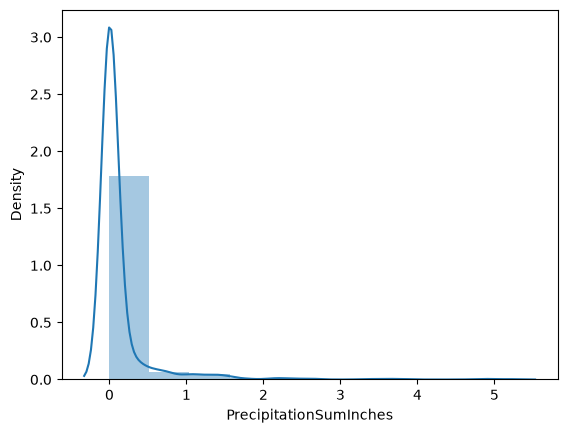

In [15]:
sns.distplot(data['PrecipitationSumInches'],bins=10)

<Axes: ylabel='PrecipitationSumInches'>

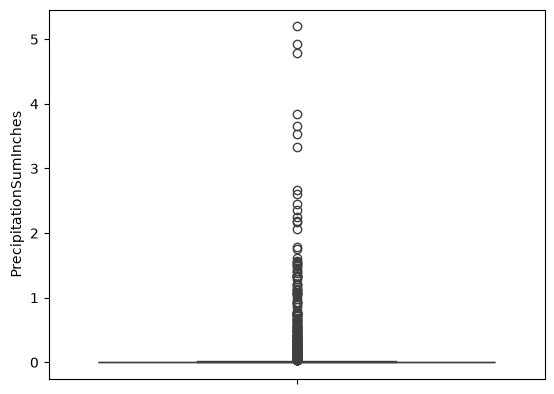

In [16]:
sns.boxplot(data['PrecipitationSumInches'])

<Axes: xlabel='Month'>

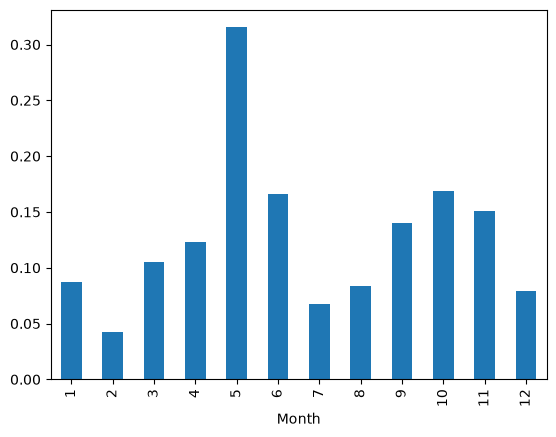

In [17]:
data.groupby('Month')['PrecipitationSumInches'].mean().plot(kind='bar')

In [18]:
print(data['PrecipitationSumInches'].dtype)

float64


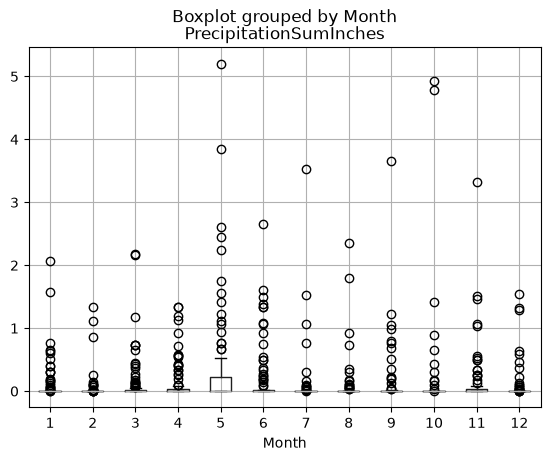

In [19]:
data.boxplot(column='PrecipitationSumInches', by='Month')
plt.show()

In [20]:
data['TempAvgF'].dtype
num_col = [i for i in data.columns if data[i].dtype == 'int64' or data[i].dtype == 'float64']

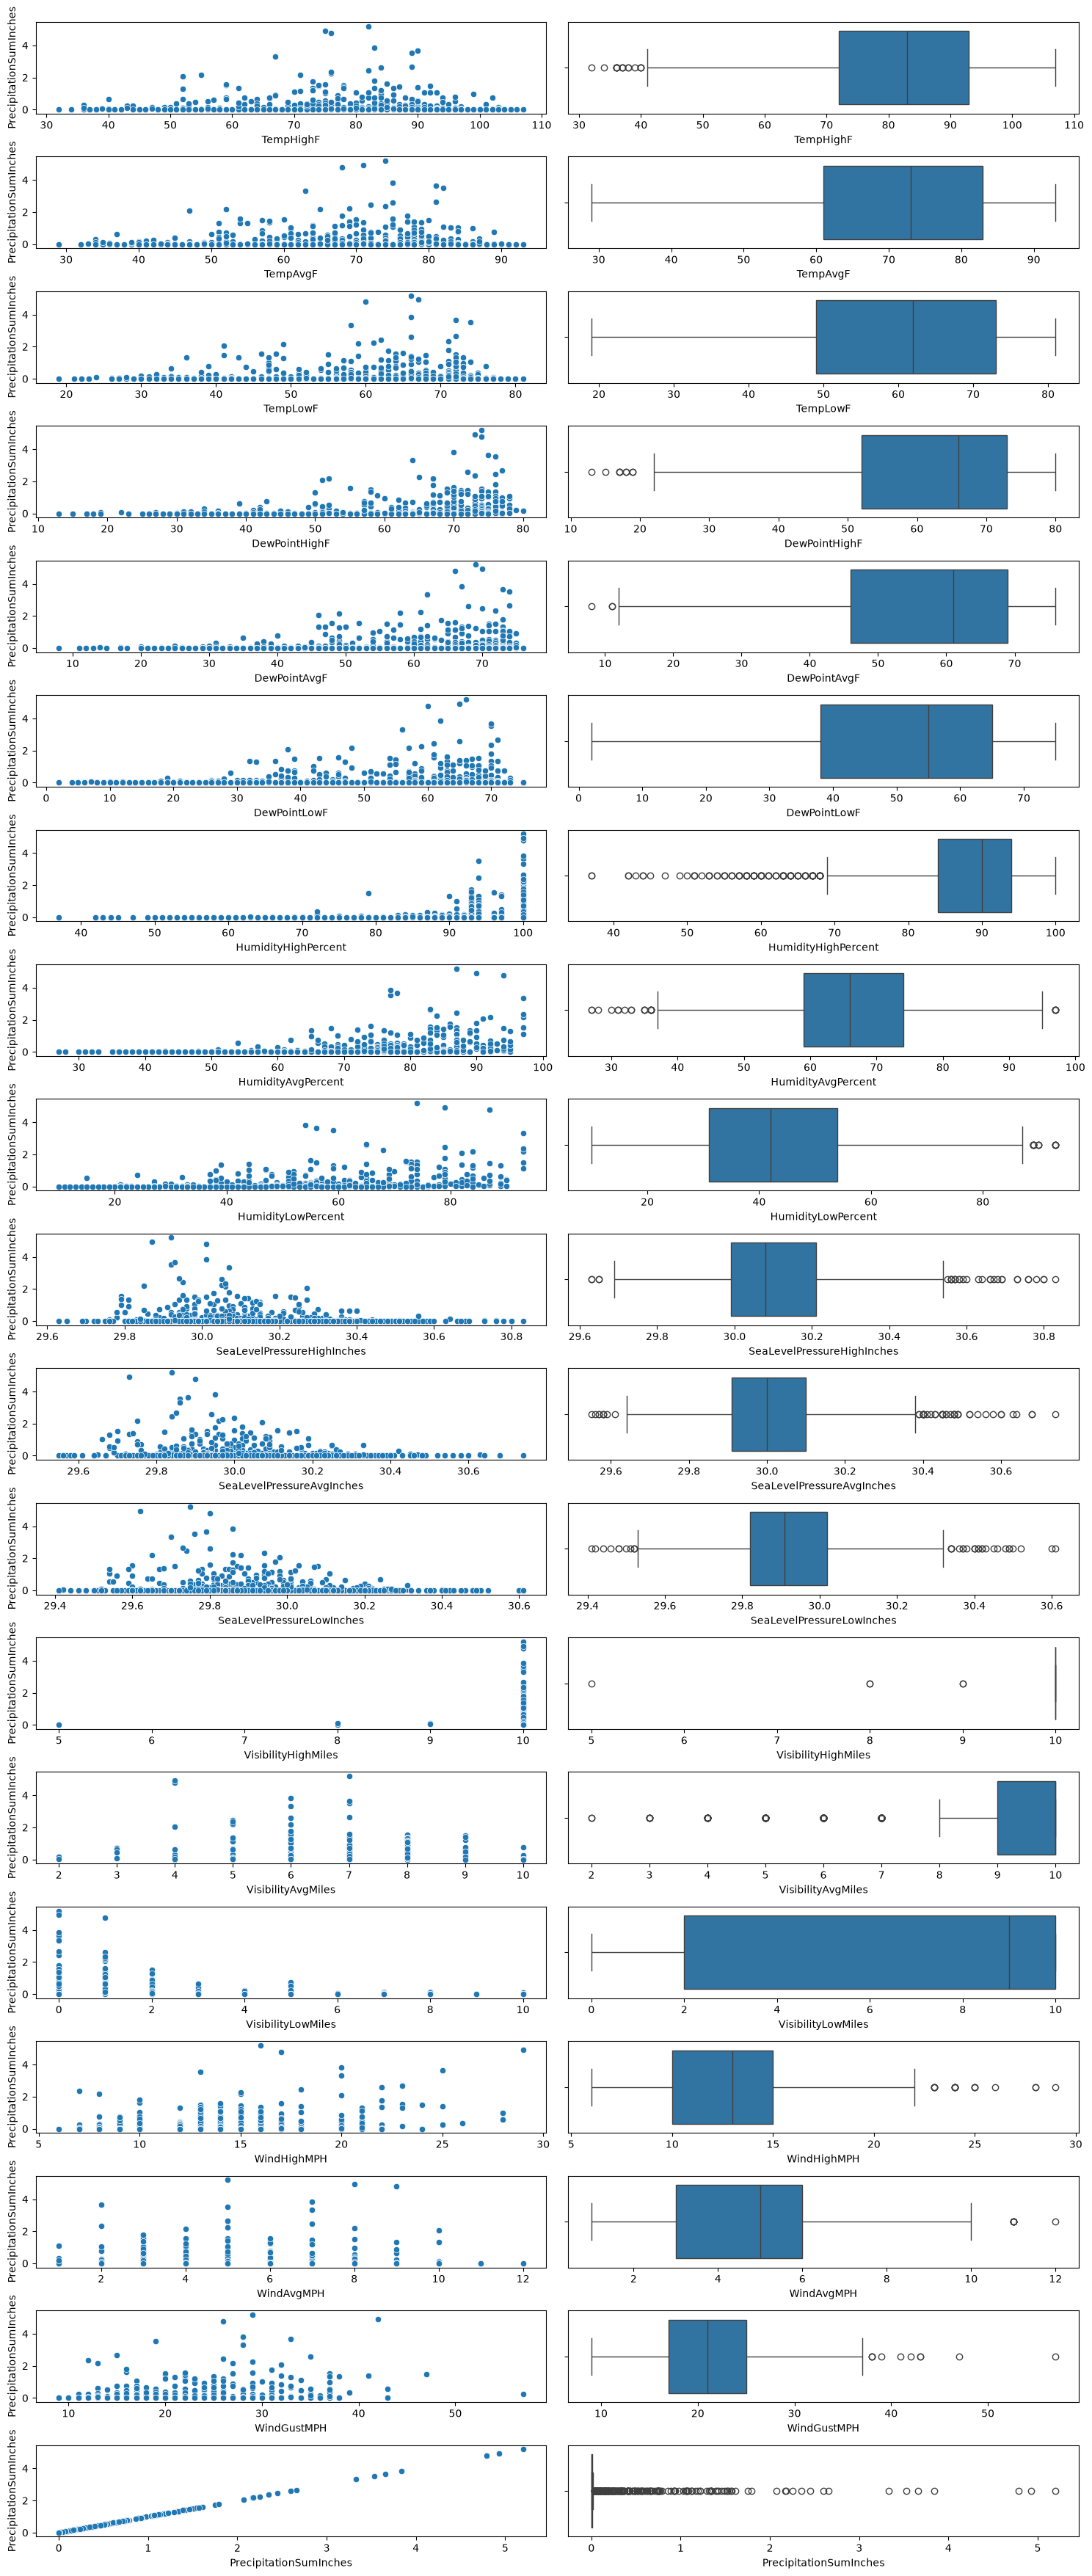

In [21]:
c = 1

plt.figure(figsize=(15, 35))

for i in num_col:
    plt.subplot(len(num_col), 2, c)
    sns.scatterplot(x=data[i], y=data['PrecipitationSumInches'])
    c += 1

    plt.subplot(len(num_col), 2, c)
    sns.boxplot(x=data[i])
    c += 1

plt.tight_layout()
plt.show()

In [22]:
# data = pd.get_dummies(data,columns=['Events'])
data2 = data[['TempAvgF','DewPointAvgF','HumidityAvgPercent','SeaLevelPressureAvgInches','VisibilityAvgMiles','WindAvgMPH','PrecipitationSumInches','Events','Year','Month']]

In [23]:
x = data.drop(columns=['PrecipitationSumInches','Events','Year'])
y = data['PrecipitationSumInches']

In [24]:
x = data.drop(columns=['PrecipitationSumInches','Events','Year'])
y = data['PrecipitationSumInches']

In [25]:
sc = StandardScaler()
x_std = sc.fit_transform(x)
x_std = pd.DataFrame(x_std,columns=x.columns)

In [26]:
x_std.describe()

,TempHighF,TempAvgF,TempLowF,DewPointHighF,DewPointAvgF,DewPointLowF,HumidityHighPercent,HumidityAvgPercent,HumidityLowPercent,SeaLevelPressureHighInches,SeaLevelPressureAvgInches,SeaLevelPressureLowInches,VisibilityHighMiles,VisibilityAvgMiles,VisibilityLowMiles,WindHighMPH,WindAvgMPH,WindGustMPH,Month
count,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03,1.183000e+03
mean,1.201256e-16,-1.741821e-16,4.805023e-17,2.042135e-16,-1.381444e-16,6.006278e-18,-2.582700e-16,2.072166e-16,9.910359e-17,-1.905792e-14,9.123537e-15,1.495563e-15,3.771943e-15,-5.766027e-16,1.501570e-17,-5.405651e-17,-1.411475e-16,-1.982072e-16,-3.603767e-17
std,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00,1.000423e+00
min,-3.299669e+00,-2.937683e+00,-2.831785e+00,-3.522648e+00,-3.230311e+00,-2.991111e+00,-4.534815e+00,-3.082923e+00,-1.985618e+00,-2.669481e+00,-2.732503e+00,-3.019742e+00,-2.905731e+01,-4.832610e+00,-1.813237e+00,-2.093586e+00,-1.922184e+00,-2.093106e+00,-1.511634e+00
25%,-6.034570e-01,-6.740262e-01,-7.393853e-01,-6.788760e-01,-6.933099e-01,-7.790590e-01,-3.342278e-01,-5.708772e-01,-7.697866e-01,-6.732410e-01,-6.488159e-01,-6.441595e-01,5.413795e-02,-9.440926e-02,-1.280568e+00,-9.290333e-01,-9.551656e-01,-7.317457e-01,-9.248374e-01
50%,1.380014e-01,1.748450e-01,1.673212e-01,3.419652e-01,3.081377e-01,2.655210e-01,2.020174e-01,-2.136725e-02,-1.329226e-01,-1.741811e-01,-1.278942e-01,-1.226900e-01,5.413795e-02,5.824765e-01,5.837749e-01,-5.561895e-02,1.185272e-02,-5.106541e-02,-4.464219e-02
75%,8.120545e-01,8.822376e-01,9.345344e-01,8.523858e-01,8.422432e-01,8.799799e-01,5.595142e-01,6.066442e-01,5.618380e-01,5.466831e-01,4.509077e-01,5.146615e-01,5.413795e-02,5.824765e-01,8.501095e-01,5.266573e-01,4.953619e-01,6.296149e-01,8.355530e-01
max,1.755729e+00,1.589630e+00,1.492508e+00,1.362806e+00,1.309585e+00,1.494439e+00,1.095759e+00,2.412177e+00,2.819810e+00,3.984651e+00,4.155240e+00,3.933183e+00,5.413795e-02,5.824765e-01,8.501095e-01,4.602591e+00,3.396417e+00,6.075058e+00,1.715748e+00


In [27]:
x_train,x_test,y_train,y_test = train_test_split(x_std,y,test_size=0.2,random_state=42)

In [28]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

In [29]:
pipeline.fit(x_train, y_train)
y_predicted = pipeline.predict(x_test)

In [30]:
print('Mean absolute error = ' + str(mean_absolute_error(y_test, y_predicted)))
print('Mean squared error = ' + str(mean_squared_error(y_test, y_predicted)))
print('R2 score = ' + str(r2_score(y_test, y_predicted)))

Mean absolute error = 0.09280780590717302
Mean squared error = 0.08213360804852321
R2 score = 0.5682410634022648


In [31]:
import joblib

joblib.dump(pipeline, "RainfallPredictionAPI/models/rainfall_pipeline.joblib")

['RainfallPredictionAPI/models/rainfall_pipeline.joblib']

In [32]:
print(x.columns.tolist())

['TempHighF', 'TempAvgF', 'TempLowF', 'DewPointHighF', 'DewPointAvgF', 'DewPointLowF', 'HumidityHighPercent', 'HumidityAvgPercent', 'HumidityLowPercent', 'SeaLevelPressureHighInches', 'SeaLevelPressureAvgInches', 'SeaLevelPressureLowInches', 'VisibilityHighMiles', 'VisibilityAvgMiles', 'VisibilityLowMiles', 'WindHighMPH', 'WindAvgMPH', 'WindGustMPH', 'Month']


In [33]:
data["PrecipitationSumInches"].describe()

count    1183.000000
mean        0.127380
std         0.450287
min         0.000000
25%         0.000000
50%         0.000000
75%         0.010000
max         5.200000
Name: PrecipitationSumInches, dtype: float64

In [34]:
print(data.max())

TempHighF                              107
TempAvgF                                93
TempLowF                                81
DewPointHighF                         80.0
DewPointAvgF                          76.0
DewPointLowF                          75.0
HumidityHighPercent                  100.0
HumidityAvgPercent                    97.0
HumidityLowPercent                    93.0
SeaLevelPressureHighInches           30.83
SeaLevelPressureAvgInches            30.74
SeaLevelPressureLowInches            30.61
VisibilityHighMiles                   10.0
VisibilityAvgMiles                    10.0
VisibilityLowMiles                    10.0
WindHighMPH                           29.0
WindAvgMPH                            12.0
WindGustMPH                           57.0
PrecipitationSumInches                 5.2
Events                        Thunderstorm
Year                                  2017
Month                                   12
dtype: object


In [35]:
preds = pipeline.predict(x_test)

print("Max prediction:", preds.max())
print("Min prediction:", preds.min())

Max prediction: 2.938299999999998
Min prediction: 0.0


In [36]:
sample = x_train.iloc[[0]]

print("Actual:", y_train.iloc[0])
print("Predicted:", pipeline.predict(sample)[0])

Actual: 0.01
Predicted: 0.03974999999999986
